In [1]:
import pandas as pd 
pd.options.mode.chained_assignment = None  # default='warn'
import numpy as np 
import matplotlib.pyplot as plt 
import matplotlib.patches as mpatches
from matplotlib.markers import MarkerStyle
import seaborn as sns 
import pickle 
from sklearn import metrics 
import sys 
import scipy.stats
import copy
from matplotlib.colors import to_rgba
import glob
import time 
import json
from sklearn.metrics import auc, roc_curve, roc_auc_score

from config import (llm_review_path, home_path, supp_table_path, figure_path_2)

sys.path.insert(1, home_path)
from common_functions import sort_dict_by_value,format_p, mean_confidence_interval, entropy, sort_dict_by_key, my_colors

In [2]:
data_output_path = llm_review_path + "source_data_csvs/"


In [3]:
def p_val_to_stars(p):
    if p <= 0.001:
        return "***"
    if p <= 0.01:
        return "**"
    if p <= 0.05:
        return "*"
    return "ns"

def save_figure(fig, name, root_path = figure_path_2, save_svg = True):
    fig.savefig(root_path + name + ".png", bbox_inches = "tight")
    if save_svg:
        fig.savefig(root_path + name + ".svg", format="svg", dpi = 1200, bbox_inches = "tight")

In [4]:
regular_aas = ['P','S','L','A','V','G','T','E','R','Q','D','F','I','H','Y','N','K','C','W','M']

def augment_masked_df_with_site_entropy(df, limit_normal_aas = True, return_entropy = True):
    df["name"] = df["ref_aa"] + df["aa_pos"].astype(str) + df["token_str"]
    df = df.loc[df["token_str"].isin(regular_aas)]
    variant_to_s1 = {}
    variant_to_adj_prob = {}
    variant_to_site_entropy = {}
    for pos, sub_df in df.groupby("aa_pos"):
        v_to_adj_score = {}
        valid_prob_total = np.sum(sub_df["score"])
        for index, row in sub_df.iterrows():
            v_to_adj_score[row["name"]] = row["score"] / valid_prob_total
        
        sub_df["adj_score"] = sub_df["name"].apply(lambda x : v_to_adj_score[x])
        
        wt_val = sub_df.loc[sub_df["ref_aa"] == sub_df["token_str"]]
        assert len(wt_val) == 1
        wt_score = wt_val.iloc[0]["adj_score"]
        
        adj_prob_list = []
        for index, row in sub_df.iterrows():
            variant_to_s1[row["name"]] = np.log(row["adj_score"]) - np.log(wt_score)
            variant_to_adj_prob[row["name"]] = row["adj_score"] / valid_prob_total
            adj_prob_list.append(row["adj_score"] / valid_prob_total)
        ent_val = entropy(adj_prob_list)
        
        for name in sub_df["name"].values: variant_to_site_entropy[name] = ent_val

    if return_entropy:
        df["site_entropy"] = df["name"].apply(lambda x : variant_to_site_entropy[x])
            
    df["s1"] = df["name"].apply(lambda x : variant_to_s1[x])
    df["adj_score"] = df["name"].apply(lambda x : variant_to_adj_prob[x])
    
    df = df.set_index("name")
    return df

In [5]:
rev_path = f"{home_path}singh/nlp_review/revisions/"



green_1 = "#357847"
coral_1 = "#E39695"
dark_blue_1 = "#2B2D42"
dark_red_1 = "#A3320B" # old UR50 color
dark_red_2 = "#d4424b"
light_blue_1 = "#0C7489"
orange_1 = "#f5a60a"
dark_orange = "darkorange"

ur_50_color = dark_red_1
ur_90_color = "seagreen"
ur_100_color = "dodgerblue"
bfd_color = "#ff7b00"

all_models = [
    "progen2_bfd",
    "progen2_medium",
    "progen2_large",
    "carp_640M",
    "carp_76M", 
    "carp_38M",
    "carp_600k",
    "prott5_xl_bfd",
    "prott5_xl",
    "protbert_bfd",
    "protbert",
    "esm_1b",
    "esm_1_UR50",
    "esm_2_15B",
    "esm_2",
    "esm_2_35M",
    "esm_1v",
    "esm_2_650M",
    "esm_1_UR100",
    "esm_1_UR50D",
    "esm_1_85M",
    "esm_2_150M",
    "esm_2_8M",
    "esm_1_43M"
]

model_to_dataset_shorthand = {m : "UR50" for m in all_models}
model_to_dataset_shorthand["prott5_xl_bfd"] = "BFD"
model_to_dataset_shorthand["progen2_medium"] = "BFD+UR90"
model_to_dataset_shorthand["progen2_large"] = "BFD+UR90"
model_to_dataset_shorthand["protbert_bfd"] = "BFD"
model_to_dataset_shorthand["protbert"] = "UR100"
model_to_dataset_shorthand["esm_1_UR100"] = "UR100"
model_to_dataset_shorthand["esm_1v"] = "UR90"
model_to_dataset_shorthand["esm_1_UR50D"] = "UR50D"
model_to_dataset_shorthand["esm_1_UR50"] = "UR50S"

model_to_color = {m : ur_50_color for m in all_models}
model_to_color["prott5_xl_bfd"] = bfd_color
model_to_color["progen2_medium"] = ur_90_color
model_to_color["progen2_large"] = ur_90_color
model_to_color["progen2_bfd"] = bfd_color
model_to_color["protbert_bfd"] = bfd_color
model_to_color["protbert"] = ur_100_color
model_to_color["esm_1_UR100"] = ur_100_color
model_to_color["esm_1v"] = ur_90_color

In [6]:
biolip_cleaned = pd.read_csv(llm_review_path + "data/biolip/biolip_cleaned.csv.gz")
biolip_cleaned["identifier"] = biolip_cleaned["PDB_ID"] + "_" + biolip_cleaned["Receptor_chain"]

len(biolip_cleaned)

537

In [7]:
biolip_header = [
    "PDB ID",
    "Receptor chain",
    "Resolution",
    "Binding site number code",
    "Ligand ID CCD",
    "Ligand chain",
    "Ligand serial number",
    "Binding site residues (with PDB residue numbering)",
    "Binding site residues (with residue re-numbered starting from 1)",
    "Catalytic site residues with PDB residue numbering",
    "Catalytic site residues with residue re-numbered starting from 1",
    "EC number",
    "GO terms",
    "Binding affinity by manual survey of the original literature. The information in '()' is the PubMed ID",
    "Binding affinity provided by the Binding MOAD database. The information in '()' is the ligand information in Binding MOAD",
    "Binding affinity provided by the PDBbind-CN database. The information in '()' is the ligand information in PDBbind-CN",
    "Binding affinity provided by the BindingDB database",
    "UniProt ID",
    "PubMed ID",
    "Residue sequence number of the ligand (field _atom_site.auth_seq_id in PDBx/mmCIF format)",
    "Receptor sequence",
] # from the biolip documentation

biolip_raw = pd.read_csv(llm_review_path + "data/biolip/BioLiP.txt", delimiter = "\t", names = biolip_header)
biolip_raw["identifier"] = biolip_raw["PDB ID"] + "_" + biolip_raw["Receptor chain"]


biolip_cleaned = pd.read_csv(llm_review_path + "data/biolip/biolip_cleaned.csv.gz")
biolip_cleaned["identifier"] = biolip_cleaned["PDB_ID"] + "_" + biolip_cleaned["Receptor_chain"]

biolip_cleaned["num_cat_sites"] = biolip_cleaned["Catalytic_site_residues_numbered"].apply(
    lambda x : len(x.split(" "))
)

biolip_cleaned["length"] = biolip_cleaned["Receptor_sequence"].apply(lambda x : len(x))

biolip_cleaned["cat_site_ratio"] = biolip_cleaned["num_cat_sites"] / biolip_cleaned["length"] 

id_to_num_cat_sites = dict(zip(biolip_cleaned["identifier"].values, biolip_cleaned["num_cat_sites"].values))
id_to_cat_site_ratio = dict(zip(biolip_cleaned["identifier"].values, biolip_cleaned["cat_site_ratio"].values))

/tmp/ipykernel_1961543/281865558.py:25: DtypeWarning: Columns (13,14) have mixed types. Specify dtype option on import or set low_memory=False.
  biolip_raw = pd.read_csv(llm_review_path + "data/biolip/BioLiP.txt", delimiter = "\t", names = biolip_header)


In [8]:
masked_site_ent_data_path = "../../../revisions/scripts/catalytic_sites/results/"

new_models = [
    "carp_600k",
    "carp_38M",
    "carp_76M",
    "carp_640M",
    "progen2_medium",
    "progen2_large",
    "progen2_bfd",
    "prott5_xl_bfd",
    "prott5_xl",
    "protbert_bfd"
]

model_to_auroc_vals = {}

model_to_average_entropy = {}


for m in new_models:
    
    res_fn =  masked_site_ent_data_path + m + "_site_entropy.pkl"

    with open(res_fn, "rb") as f:
        model_site_entropy_data = pickle.load(f)
    f.close()

    auroc_dict = {}
    ent_vals = {}
    for index, row in biolip_cleaned.iterrows():
        seq = [*row["Receptor_sequence"]]
        ident = row["identifier"]


        cat_sites = row["Catalytic_site_residues_numbered"].split(" ")
        cat_site_ref = []
        cat_site_pos = []
        for cs in cat_sites:
            ref = cs[0]
            pos = int(cs[1:])
            cat_site_ref.append(ref)
            cat_site_pos.append(pos)
            assert seq[pos - 1] == ref

        labels = np.zeros(len(seq))
        for cs_pos in cat_site_pos:
            labels[cs_pos - 1] = 1

        positional_entropy = model_site_entropy_data[ident]
        
        ent_vals[ident] = np.mean(list(model_site_entropy_data[ident].values()))
        predictions = []

        for i in range(len(labels)):
            predictions.append(positional_entropy[i + 1])

        fpr, tpr, thresholds = metrics.roc_curve(labels, predictions, pos_label=0)
        auroc = metrics.auc(fpr, tpr)
        auroc_dict[ident] = auroc
    
    model_to_auroc_vals[m] = auroc_dict
    model_to_average_entropy[m] = ent_vals 

In [9]:

model_info = pd.read_csv("model_info_2.csv")
model_to_base_str = dict(zip(model_info["model_string"].values, model_info["base_string"].values))
model_to_params_str = dict(zip(model_info["model_string"].values, model_info["params_string"].values))
model_to_dataset_str = dict(zip(model_info["model_string"].values, model_info["dataset_string"].values))

conv_key = {
    "ProtBERT" : "protbert",
    "ESM-1 (43M)" : "esm_1_43M",
    "ESM-1 (85M)" : "esm_1_85M",
    "ESM-1 (670M) UR50S" : "esm_1_UR50",
    "ESM-1 (670M) UR50D" : "esm_1_UR50D",
    "ESM-1 (670M) UR100" : "esm_1_UR100",
    "ESM-1b" : "esm_1b",
    "ESM-1v" : "esm_1v",
    "ESM-2 (8M)" : "esm_2_8M",
    "ESM-2 (35M)" : "esm_2_35M",
    "ESM-2 (150M)" : "esm_2_150M",
    "ESM-2 (650M)" : "esm_2_650M",
    "ESM-2 (3B)" : "esm_2",
    "ESM-2 (15B)" : "esm_2_15B"
}

old_model_results = pd.read_csv(supp_table_path + "all_model_performance_cat_site.csv")
old_model_results["model_key"] = old_model_results["Model"].apply(lambda x : conv_key[x])

for m, sub_df in old_model_results.groupby("model_key"):
    model_to_auroc_vals[m] = dict(zip( sub_df["Identifier"].values , sub_df["Performance"].values))
    
old_model_entropy_values = pd.read_csv(supp_table_path + "average_site_entropy_cat_sites.csv")
old_model_entropy_values["model_key"] = old_model_entropy_values["Model"].apply(lambda x : conv_key[x])

for m, sub_df in old_model_entropy_values.groupby("model_key"):
    model_to_average_entropy[m] = dict(zip( sub_df["Identifier"].values , sub_df["Average Site Entropy"].values))
        

/tmp/ipykernel_1961543/3178488342.py:80: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")


Text(-0.8, -0.185, 'Training Set')

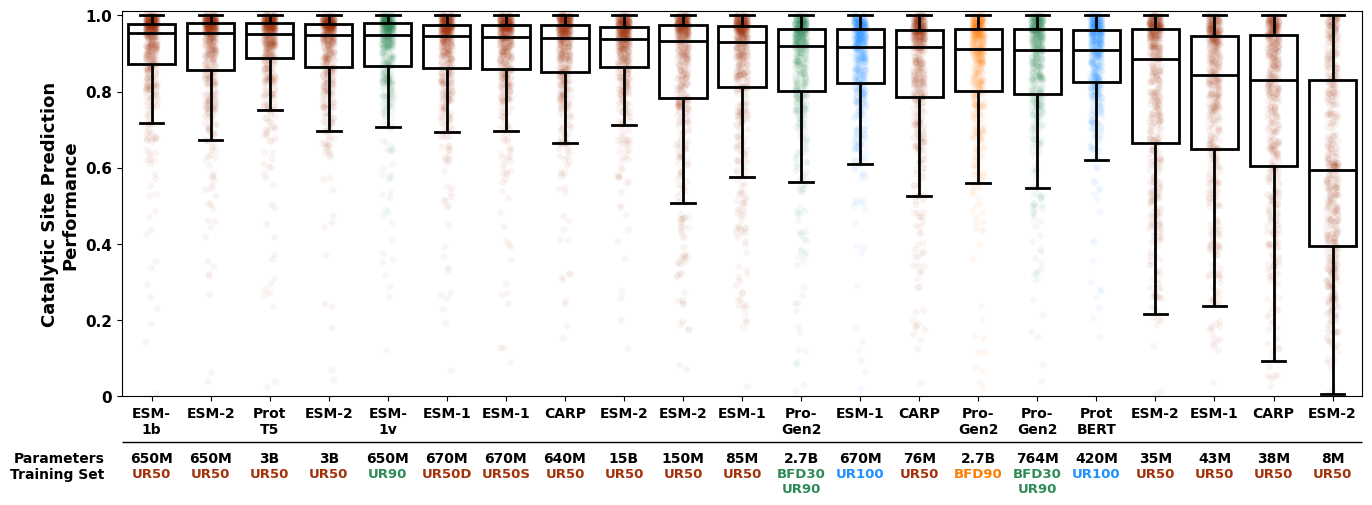

In [10]:
x = []
data = []
x_ticklabels = []

my_pal = []

dataset_str_list = []
params_str_list = []

model_to_median = {}

model_to_ci = {}
for c, v in model_to_auroc_vals.items():
    
    if c in ["prott5_xl_bfd", "carp_600k", "protbert_bfd"]:
        continue 
        
    model_to_median[c] = np.median(list(v.values()))
    model_to_ci[c] = mean_confidence_interval(list(v.values()))
    
model_to_median = sort_dict_by_value(model_to_median, reverse = True)


for i, (m_name, mean_val) in enumerate(model_to_median.items()):
    
    
    x.append(i)
    label_str = (
        model_to_base_str[m_name]
    )
    
    params_str_list.append(model_to_params_str[m_name] )
    dataset_str_list.append(model_to_dataset_str[m_name].replace("UR", "UR ").replace("-", "").replace("/", "\n"))
    x_ticklabels.append(label_str)
    
    data.append(list(model_to_auroc_vals[m_name].values()))
    my_pal.append(model_to_color[m_name])
    

fig, ax = plt.subplots(figsize = (16,5))

sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, facecolor=(0, 0, 0, 0), edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False
)


sns.stripplot(
    data, 
    zorder = 1, 
    alpha = 0.05,
    palette = my_pal
)

string_replacements = {
    "ProtBERT" : "Prot\nBERT",
    "ESM-1v" : "ESM-\n1v",
    "ESM-1b" : "ESM-\n1b",
    "ProtT5" : "Prot\nT5",
    "PG2" : "Pro-\nGen2"
}

x_ticklabels = list(map(lambda x : string_replacements[x] if x in string_replacements.keys() else x, x_ticklabels))

for i, (m_name, _) in enumerate(model_to_median.items()):

    
    ax.text(i, -0.145, params_str_list[i],  horizontalalignment = "center", fontsize = 10,  verticalalignment = "top", fontweight = "bold")

    ds_str = dataset_str_list[i].replace(" ", "")
    if ds_str == "BFD100":
        ds_str = "BFD\n100"
    ax.text(i, -0.185, ds_str, color = model_to_color[m_name], horizontalalignment = "center", fontsize = 9.5,  verticalalignment = "top", fontweight = "bold")

ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")
ax.set_yticks([0, 0.2,0.4,0.6,0.8,1.0])
ax.set_yticklabels([0,0.2,0.4,0.6,0.8,1.0], fontweight = "bold", fontsize = 11)

r1 = mpatches.Rectangle((-0.5, -0.12), len(data), 0.0001, color = "black", clip_on = False)
ax.add_patch(r1)

ax.set_ylabel("Catalytic Site Prediction\nPerformance", fontweight = "bold", fontsize = 13)
ax.set_ylim(bottom = 0, top = 1.01)

ax.text(-0.8, -0.145, "Parameters", horizontalalignment = "right", fontsize = 10, fontweight = "bold", verticalalignment = "top")
ax.text(-0.8, -0.185, "Training Set", horizontalalignment = "right", fontsize = 10,  verticalalignment = "top", fontweight = "bold")


In [11]:
corr_entropy_df = pd.DataFrame(model_to_average_entropy)
corr_entropy_df.to_csv(supp_table_path + "revisions/corr_entropy_df_cat_sites.csv")

In [12]:
corr_df = pd.DataFrame(model_to_auroc_vals)
corr_df.to_csv(supp_table_path + "revisions/corr_df_cat_sites.csv")

/tmp/ipykernel_1961543/3260802034.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")


Text(0, 0.5, 'Average Masked Entropy')

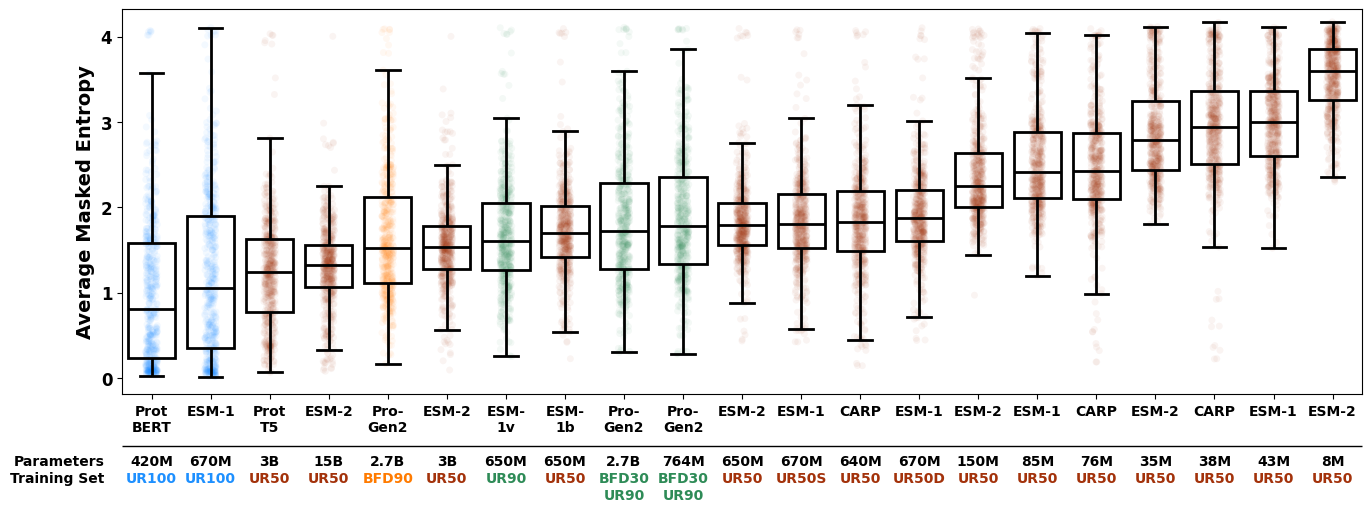

In [13]:
entropy_df = pd.DataFrame(model_to_average_entropy).drop(columns  = ["carp_600k", "prott5_xl_bfd", "protbert_bfd"])

model_to_median = {c : np.median(entropy_df[c]) for c in entropy_df.columns}
model_to_median = sort_dict_by_value(model_to_median)  

data = []
x = []
x_ticklabels = []
params_str_list = []
dataset_str_list = []
my_pal = {}
for i, (m, median_val) in enumerate(model_to_median.items()):
    x.append(i)
    
    data.append(list(entropy_df[m].values))
    my_pal[i] = model_to_color[m] # old UR50 color
    label_str = (
        model_to_base_str[m]
    )
    
    params_str_list.append(model_to_params_str[m] )
    dataset_str_list.append(model_to_dataset_str[m].replace("UR", "UR ").replace("-", "").replace("/", "\n"))
    x_ticklabels.append(label_str)
 
fig, ax = plt.subplots(figsize = (16,5))

sns.boxplot(
    data, 
    color = "white", 
    boxprops=dict(linewidth=2, facecolor=(0, 0, 0, 0), edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    showfliers = False
)


sns.stripplot(
    data, 
    zorder = 1, 
    alpha = 0.05,
    palette = my_pal
)

string_replacements = {
    "ProtBERT" : "Prot\nBERT",
    "ESM-1v" : "ESM-\n1v",
    "ESM-1b" : "ESM-\n1b",
    "ProtT5" : "Prot\nT5",
    "PG2" : "Pro-\nGen2"
}

x_ticklabels = list(map(lambda x : string_replacements[x] if x in string_replacements.keys() else x, x_ticklabels))


for i, (m_name, _) in enumerate(model_to_median.items()):
    ax.text(i, -0.9, params_str_list[i],  horizontalalignment = "center", fontsize = 10,  verticalalignment = "top", fontweight = "bold")

    ax.text(i, -1.1, dataset_str_list[i].replace(" ", "").replace("BFD100", "BFD\n100"), color = model_to_color[m_name], horizontalalignment = "center", fontsize = 10,  verticalalignment = "top", fontweight = "bold")

r1 = mpatches.Rectangle((-0.5, -0.8), len(data), 0.0001, color = "black", clip_on = False)
ax.add_patch(r1)


ax.text(-0.8, -0.9, "Parameters", horizontalalignment = "right", fontsize = 10, fontweight = "bold", verticalalignment = "top")
ax.text(-0.8, -1.1, "Training Set", horizontalalignment = "right", fontsize = 10,  verticalalignment = "top", fontweight = "bold")


ax.set_xticklabels(x_ticklabels, fontsize = 10, fontweight = "bold")
ax.set_yticks([0,1,2,3,4])
ax.set_ylim(top = np.log2(20))
ax.set_yticklabels([0,1,2,3,4],fontsize = 12, fontweight = "bold")
ax.set_ylabel("Average Masked Entropy", fontsize = 14, fontweight = "bold")



"prott5_xl"
"esm_1v"
"esm_2"
"esm_1b"
"esm_2_650M"
"esm_2_15B"
"esm_1_UR50"
"esm_1_UR50D"
"carp_640M"
"protbert"
"esm_1_UR100"
"progen2_bfd"
"progen2_medium"
"esm_1_85M"
"progen2_large"
"esm_2_150M"
"carp_76M"
"esm_2_35M"
"esm_1_43M"
"carp_38M"
"esm_2_8M"


/tmp/ipykernel_1961543/3237754973.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x, orient = "h", ax = ax, palette = my_pal,  zorder = 100, linewidth=1.2, edgecolor = "black")
/tmp/ipykernel_1961543/3237754973.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels, fontweight = "bold")


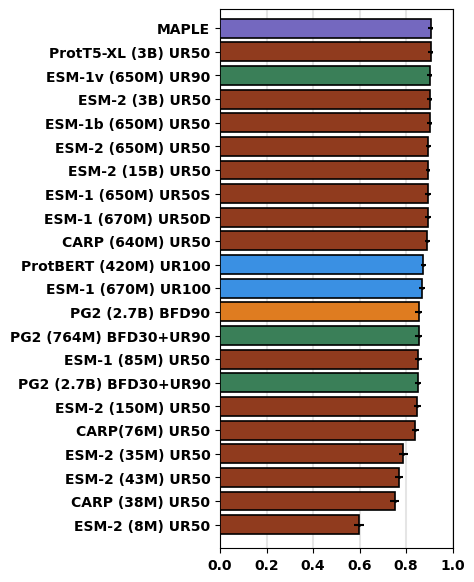

In [14]:
model_to_display_name_c = {
    "esm_1v" : "ESM-1v (650M) UR90",
    "esm_2_650M" : "ESM-2 (650M) UR50",
    "esm_2": "ESM-2 (3B) UR50",
    "esm_2_15B": "ESM-2 (15B) UR50",
    "prott5_xl" : "ProtT5-XL (3B) UR50",
    "esm_1_UR50D" : "ESM-1 (670M) UR50D",
    "esm_1b": "ESM-1b (650M) UR50",
    "carp_640M": "CARP (640M) UR50",
    "esm_1_UR50": "ESM-1 (650M) UR50S",
    "esm_1_UR100": "ESM-1 (670M) UR100",
    "protbert": "ProtBERT (420M) UR100",
    "protbert_bfd": "ProtBERT (420M) BFD100",
    "esm_2_150M": "ESM-2 (150M) UR50",
    "carp_76M": "CARP(76M) UR50",
    "progen2_bfd": "PG2 (2.7B) BFD90",
    "progen2_large": "PG2 (2.7B) BFD30+UR90",
    "progen2_medium": "PG2 (764M) BFD30+UR90",
    "esm_1_85M": "ESM-1 (85M) UR50",
    "carp_38M": "CARP (38M) UR50",
    "esm_2_35M": "ESM-2 (35M) UR50",
    "esm_1_43M": "ESM-2 (43M) UR50",
    "esm_2_8M": "ESM-2 (8M) UR50"
}


maple_details = pd.read_csv(supp_table_path + "entropy_optimal_model_choices_cat_sites.csv")
maple_mean, maple_ci_l, maple_ci_h = mean_confidence_interval(maple_details["Optimal Model Performance"].values)


corr_df_plotting = pd.DataFrame(model_to_auroc_vals) # not actually correlations, just name consistency with other files
corr_df_plotting = corr_df_plotting.drop(columns = ["carp_600k", "prott5_xl_bfd", "protbert_bfd"])
y_pal = []

dataset_str_list = []
params_str_list = []
labels = []
model_to_mean = {}
my_pal = []


model_to_ci = {}
for c in corr_df_plotting.columns:
    model_to_mean[c] = np.mean(corr_df_plotting[c])
    model_to_ci[c] = mean_confidence_interval(corr_df_plotting[c])
    
    
model_to_mean = sort_dict_by_value(model_to_mean, reverse = True)

y_val = 0 

x = []
y = []
model_list = []
err_vals = []
err_vals.append([maple_mean - maple_ci_l, maple_ci_h - maple_mean])
    
y.append(y_val)
x.append(np.mean(maple_details["Optimal Model Performance"].values))

labels.append("MAPLE")
my_pal.append("slateblue")

for k, v in model_to_mean.items():
    
    if k not in corr_df_plotting.columns:
        continue 
        
    y_val += 1
    y.append(y_val)
    x.append(v)
    err_vals.append([v - model_to_ci[k][1], model_to_ci[k][2] - v])
    my_pal.append(model_to_color[k])
    labels.append(model_to_display_name_c[k])
    print("\"" + k + "\"")
    
fig, ax = plt.subplots(figsize = (3,7))

sns.barplot(x, orient = "h", ax = ax, palette = my_pal,  zorder = 100, linewidth=1.2, edgecolor = "black")
ax.set_xticks([0.,0.2,0.4,0.6, 0.8, 1.0])
ax.set_xticklabels(ax.get_xticklabels(), fontweight = "bold")
ax.set_xlim(left = -0.0, right = 1.0)

ax.set_ylim(top = -0.8, bottom = 22)

ax.set_yticklabels(labels, fontweight = "bold")

ax.scatter(x, y, color = "black", s = 1)
ax.errorbar(x, y, xerr = np.array(err_vals).T, fmt = ".", zorder = 1000, markersize = 1, color = "black")
for x_val in ax.get_xticks():
    ax.axvline(x = x_val, zorder = 0, color = "black", alpha = 0.1)


In [15]:
err_vals_upper = x + np.array(err_vals)[:, 0]
err_vals_lower = x - np.array(err_vals)[:, 1]

data_export = {
    "model" : labels,
    "mean" : x,
    "ci_upper" : err_vals_upper,
    "ci_lower" : err_vals_lower
}

data_df_out = pd.DataFrame(data_export)

data_df_out.to_csv(data_output_path + "fig_4/data_4h.csv", index = False)

In [16]:
maple_details = pd.read_csv(supp_table_path + "entropy_optimal_model_choices_cat_sites.csv")

maple_details

,Identifier,Task,Optimal Model Performance,Optimal Model Choice,Optimal Model Average Site Entropy
0,7pcy_A,Catalytic Site Identification,0.989362,ESM-2 (3B),1.040581
1,1bxo_A,Catalytic Site Identification,0.968807,ESM-1b,1.301806
2,3eng_A,Catalytic Site Identification,0.954976,ESM-2 (3B),1.194362
3,1isv_B,Catalytic Site Identification,0.974478,ESM-2 (650M),1.214200
4,1pla_A,Catalytic Site Identification,1.000000,ESM-2 (650M),1.464336
...,...,...,...,...,...
532,2qes_A,Catalytic Site Identification,0.917313,ESM-2 (15B),1.803693
533,1elt_A,Catalytic Site Identification,0.914535,ESM-1 (670M) UR50S,1.265815
534,1zbk_A,Catalytic Site Identification,0.624650,ESM-1 (670M) UR100,1.221542
535,5tj9_C,Catalytic Site Identification,0.887734,ProtBERT,1.674754


In [17]:



homolog_counts_a = pd.read_csv(supp_table_path + "homologs_all_datasets_cat_sites.csv", index_col = "Identifier")

bfd_files = glob.glob("../../../revisions/scripts/homolog_searches/count_results/cat_sites_full/*bfd*")



all_bfd_counts = {}

for fn in bfd_files:
    bfd_df = pd.read_csv(fn)
    for index, row in bfd_df.iterrows():
        ident = row["identifier"]
        homs = row["homologs_james_definition"]
        
        if ident in all_bfd_counts.keys():
            all_bfd_counts[ident] += homs
        else:
            all_bfd_counts[ident] = homs
#             
homolog_counts_a["BFD"] = all_bfd_counts

homolog_counts_a.to_csv(supp_table_path + "revisions/r_homologs_all_datasets_cat_sites.csv")

In [18]:
model_to_base_str = {
     'esm_1_85M' : "ESM-1",
     'carp_76M': "CARP",
     'esm_1_43M': "ESM-1",
     'esm_2_150M': "ESM-2",
     'carp_38M' : "CARP",
     'esm_2_35M': "ESM-2",
     'esm_1_UR50': "ESM-1",
     'esm_1_UR50D': "ESM-1",
     'esm_1b': "ESM\n1b",
     'carp_640M' : "CARP",
     'esm_2_650M' : "ESM-2",
     'prott5_xl' : "Prot\nT5",
     'esm_2' : "ESM-2",
     'esm_2_8M' : "ESM-2",
     'esm_2_15B' : "ESM-2",
     'carp_600k' : "CARP",
     'protbert_bfd': "Prot\nBERT",
     'progen2_bfd' : "PG2",
     'progen2_medium': "PG2",
     'progen2_large': "PG2",
     'esm_1v' : "ESM\n1v",
     'esm_1_UR100' : "ESM-1",
     'protbert' : "Prot\nBERT"
}

model_to_ds_shorthand_2 = {
     'esm_1_85M': 'UR50',
     'carp_76M': 'UR50',
     'esm_1_43M': 'UR50',
     'esm_2_150M': 'UR50',
     'carp_38M': 'UR50',
     'esm_2_35M': 'UR50',
     'esm_1_UR50': 'UR50S',
     'esm_1_UR50D': 'UR50D',
     'esm_1b': 'UR50',
     'carp_640M': 'UR50',
     'esm_2_650M': 'UR50',
     'prott5_xl': 'UR50',
     'esm_2': 'UR50',
     'esm_2_8M': 'UR50',
     'esm_2_15B': 'UR50',
     'protbert_bfd': 'BFD\n100',
     'progen2_bfd': 'BFD90',
     'progen2_medium': 'UR90\nBFD30',
     'progen2_large': 'UR90\nBFD30',
     'esm_1v': 'UR90',
     'esm_1_UR100': 'UR100',
     'protbert': 'UR100'
}

model_to_params_str = {
     'esm_1_43M': '43M',
     'esm_1_85M': '85M',
     'esm_1b': '650M',
     'esm_1_UR100': '670M',
     'esm_1_UR50D': '670M',
     'esm_1_UR50': '670M',
     'esm_1v': '650M',
     'esm_2': '3B',
     'esm_2_150M': '150M',
     'esm_2_15B': '15B',
     'esm_2_35M': '35M',
     'esm_2_650M': '650M',
     'esm_2_8M': '8M',
     'protbert': '420M',
     'protbert_bfd': '420M',
     'carp_640M': '640M',
     'carp_38M': '38M',
     'carp_76M': '76M',
     'progen2_large': '2.7B',
     'progen2_medium': '764M',
     'progen2_bfd': '2.7B',
     'prott5_xl': '3B',
}

21

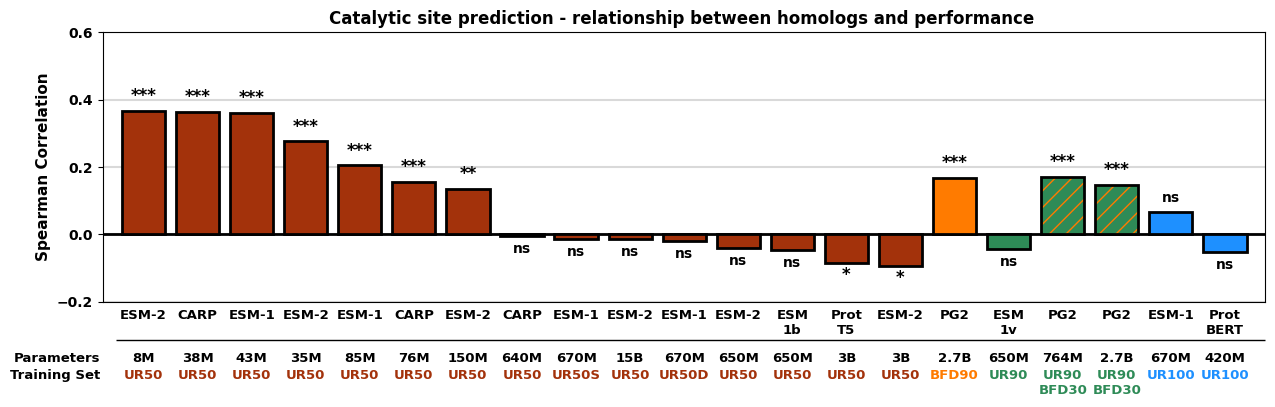

In [19]:


ur_90_models = ["esm_1v"]
dual_models = ["progen2_medium", "progen2_large"]
bfd_models = ["progen2_bfd"]
ur_100_models = ["esm_1_UR100", "protbert"]

homolog_counts_a["dual_col"] = homolog_counts_a["UniRef90"] + homolog_counts_a["BFD"]

plotting_info = []

for model in corr_df.columns:
    if model in ["carp_600k", "prott5_xl_bfd", "protbert_bfd"]:
        continue 
    performance_vals = corr_df[model].to_dict()
    df_str = "UR50"
    color = ur_50_color
    if model in ur_90_models:
        counts_dict = homolog_counts_a["UniRef90"].to_dict()
        df_str = "UR90"
        color = ur_90_color
    elif model in dual_models:
        counts_dict = homolog_counts_a["UniRef90"].to_dict()
        df_str = "DUAL"
        color = ur_90_color
    elif model in bfd_models:
        counts_dict = homolog_counts_a["BFD"].to_dict()
        df_str = "BFD"
        color = bfd_color
    elif model in ur_100_models:
        counts_dict = homolog_counts_a["UniRef100"].to_dict()
        df_str = "UR100"
        color = ur_100_color
    else:
        counts_dict = homolog_counts_a["UniRef50"].to_dict()
        
    x1 = []
    x2 = []
    for k, v in performance_vals.items():
        x1.append(v)
        x2.append(counts_dict[k])
    
    corr, p = scipy.stats.spearmanr(x1, x2)
    
    plotting_info.append([model, corr, p, df_str, color])
    
plotting_info = pd.DataFrame(plotting_info, columns = ["model", "corr", "p", "df_str", "color"])

plotting_info_corrs = copy.deepcopy(plotting_info)

ur_50_df = plotting_info.loc[plotting_info["df_str"] == "UR50"].sort_values(by = "corr", ascending = False)
bfd_df = plotting_info.loc[plotting_info["df_str"] == "BFD"].sort_values(by = "corr", ascending = False)
ur_90_df = plotting_info.loc[plotting_info["df_str"] == "UR90"].sort_values(by = "corr", ascending = False)
dual_df = plotting_info.loc[plotting_info["df_str"] == "DUAL"].sort_values(by = "corr", ascending = False)
ur_100_df = plotting_info.loc[plotting_info["df_str"] == "UR100"].sort_values(by = "corr", ascending = False)

plotting_df = pd.concat([ur_50_df,bfd_df, ur_90_df,dual_df,ur_100_df])

x = []
y = []
stars_list = []
m_list = []
p_list = []

color_list = []
hatch_list = []

for i, (index, row) in enumerate(plotting_df.iterrows()):
    y.append(row["corr"])
    x.append(i)
    stars_list.append(p_val_to_stars(row["p"]))
    p_list.append(row["p"])
    
    m_list.append(row["model"])
    color_list.append(row["color"])
    
    if row["model"] in dual_models:
        hatch_list.append("//")
    else:
        hatch_list.append("")
    
fig, ax = plt.subplots(figsize = (15, 3.5))
bars  = ax.bar(x, y,  edgecolor = "black", linewidth = 2, zorder = 100, hatch = hatch_list, color = color_list)

for bar in bars:
    bar._hatch_color = to_rgba(bfd_color) 
    
ax.axhline(y = 0,  color = "black", linewidth = 2)


for i, (index, row) in enumerate(plotting_df.iterrows()):
    y_val = row["corr"]
    star_pos = y_val + 0.03
    if y_val < 0:
        star_pos = y_val - 0.05
        
    stars = stars_list[i]
    
    if stars == "ns":
        fs = 10
    else:
        fs = 12
    
    ax.text(i, star_pos, stars, horizontalalignment = "center", fontsize = fs, fontweight = "bold")
    
    ax.text(i, -0.22, model_to_base_str[row["model"]], fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")
    ax.text(i, -0.35, model_to_params_str[row["model"]], fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")
    
    c = row["color"]
    ax.text(i, -0.4, model_to_ds_shorthand_2[row["model"]], color = c, fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")

ax.set_xlim(left = -0.75, right = len(plotting_df) - 0.25)
ax.set_yticks([-0.2,0,0.2,0.4,0.6])
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15, zorder = 1)
    
ax.set_xticks([])

r1 = mpatches.Rectangle((-0.5, -0.315), len(x) + 0.25, 0.0001, color = "black", clip_on = False)
ax.add_patch(r1)


ax.text(-0.8, -0.35, "Parameters", horizontalalignment = "right", fontsize = 9.5, fontweight = "bold", verticalalignment = "top")
ax.text(-0.8, -0.4, "Training Set", horizontalalignment = "right", fontsize = 9.5,  verticalalignment = "top", fontweight = "bold")

ax.set_ylabel("Spearman Correlation", fontweight = "bold", fontsize = 11)
ax.set_title("Catalytic site prediction - relationship between homologs and performance ", fontweight = "bold", fontsize = 12)

len(y)

In [20]:
data_export = pd.DataFrame({
    "model" : m_list,
    "spearman_correlation" : y,
    "spearman_p_value" : p_list
}) 

data_export["model"] = data_export["model"].apply(lambda x : model_to_display_name_c[x])

data_export.to_csv(data_output_path + "fig_E2/data_E2a.csv", index = False)

Text(0.5, 1.0, 'ESM-1 (670M) UR100\nPerformance Relationship to Other Models\nCatalytic Site Identification Proteins')

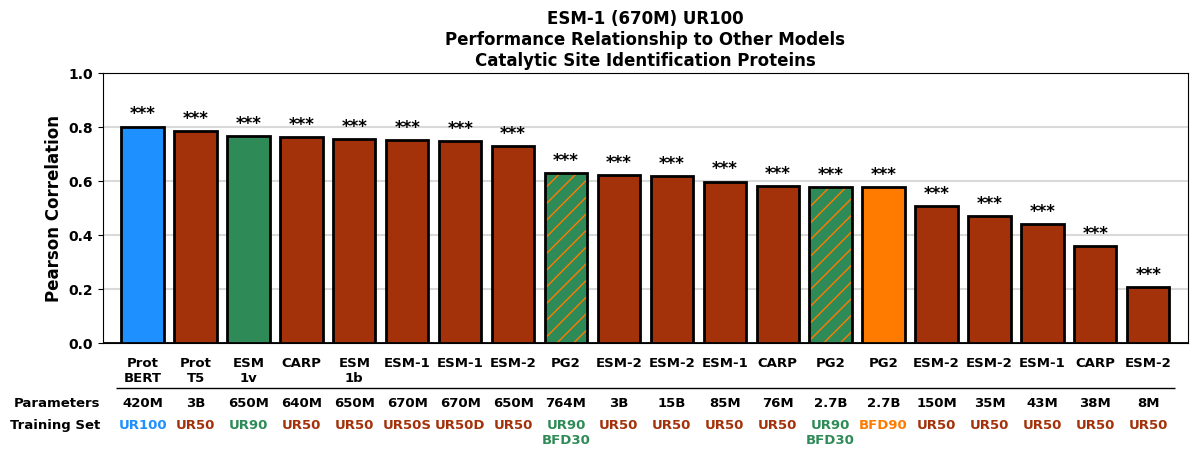

In [21]:
## correlation with UR100 model

esm_1_ur100_res = corr_df["esm_1_UR100"].to_dict()
plotting_info = []

for m in corr_df.columns:
    if m in ["carp_600k", "prott5_xl_bfd", "protbert_bfd"]:
        continue
    
    if m == "esm_1_UR100":
        continue 
        
    x1 = []
    x2 = []
    d1 = corr_df[m].to_dict()
    
    for k,v in esm_1_ur100_res.items():
        x1.append(v)
        x2.append(d1[k])
        
    corr, p = scipy.stats.pearsonr(x1,x2)
    
    plotting_info.append([m, corr, p])
    

    
plotting_info = pd.DataFrame(plotting_info, columns = ["model", "corr", "p"])   

plotting_info = plotting_info.sort_values(by = "corr", ascending = False)
m_to_color = dict(zip(plotting_info_corrs["model"].values, plotting_info_corrs["color"].values))
m_to_df_str = dict(zip(plotting_info_corrs["model"].values, plotting_info_corrs["df_str"].values))

plotting_info["color"] = plotting_info["model"].apply(lambda x : m_to_color[x])
plotting_info["df_str"] = plotting_info["model"].apply(lambda x : m_to_df_str[x])

fig, ax = plt.subplots(figsize = (14, 3.5))

x = []
y = []
stars_list = []
m_list = []
color_list = []
hatch_list = []

for i, (index, row) in enumerate(plotting_info.iterrows()):
    model = row["model"]
    x.append(i)
    y.append(row["corr"])
    color_list.append(row["color"])
    stars_list.append(p_val_to_stars(row["p"]))
    
    if row["df_str"] == "DUAL":
        hatch_list.append("//")
    else:
        hatch_list.append("")
      
bars  = ax.bar(x, y,  edgecolor = "black", linewidth = 2, zorder = 100, hatch = hatch_list, color = color_list)

for bar in bars:
    bar._hatch_color = to_rgba(bfd_color) 
    
ax.axhline(y = 0,  color = "black", linewidth = 2)

for i, (index, row) in enumerate(plotting_info.iterrows()):
    
    y_val = row["corr"]
    star_pos = y_val + 0.03
    if y_val < 0:
        star_pos = y_val - 0.05
        
    stars = stars_list[i]
    
    if stars == "ns":
        fs = 10
    else:
        fs = 12
    
    ax.text(i, star_pos, stars, horizontalalignment = "center", fontsize = fs, fontweight = "bold")
    
    ax.text(i, -0.05, model_to_base_str[row["model"]], fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")
    ax.text(i, -0.2, model_to_params_str[row["model"]], fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")
    
    c = row["color"]
    ax.text(i, -0.28, model_to_ds_shorthand_2[row["model"]], color = c, fontsize = 9.5, horizontalalignment = "center", verticalalignment = "top", fontweight="bold")

ax.set_xlim(left = -0.75, right = len(plotting_info) - 0.25)
ax.set_yticks([0,0.2,0.4,0.6,0.8,1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15, zorder = 1)
    
ax.set_xticks([])

r1 = mpatches.Rectangle((-0.5, -0.17), len(data) - 1, 0.0001, color = "black", clip_on = False)
ax.add_patch(r1)


ax.text(-0.8, -0.2, "Parameters", horizontalalignment = "right", fontsize = 9.5, fontweight = "bold", verticalalignment = "top")
ax.text(-0.8, -0.28, "Training Set", horizontalalignment = "right", fontsize = 9.5,  verticalalignment = "top", fontweight = "bold")

ax.set_ylabel("Pearson Correlation", fontweight = "bold", fontsize = 12)

ax.set_title("ESM-1 (670M) UR100\nPerformance Relationship to Other Models\nCatalytic Site Identification Proteins", fontweight = "bold", fontsize = 12)

Text(0.5, 1.0, 'Catalytic Site\nIdentification Proteins')

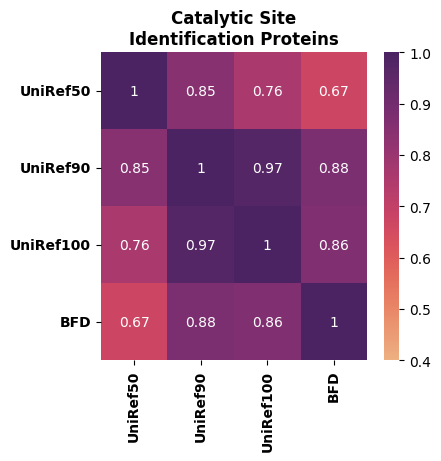

In [22]:


labels = ["UniRef50","UniRef90", "UniRef100",  "BFD"]
data = []

for i in labels:
    lst = []
    for j in labels:
        corr, p = scipy.stats.spearmanr(homolog_counts_a[i], homolog_counts_a[j].values)
        lst.append(corr)
    data.append(lst)
    
fig, ax = plt.subplots(figsize = (4.3,4))

sns.heatmap(data, annot = True,vmin=0.4, vmax=1, cmap = "flare")

ax.set_yticklabels(labels, rotation = 0, fontweight = "bold")
ax.set_xticklabels(labels, rotation = 90, fontweight = "bold")
ax.set_title("Catalytic Site\nIdentification Proteins", fontweight = "bold")